# Lecture 3 — Model Answer
## Line Charts: CO2 Emissions

In [37]:
import pandas as pd
import plotly.express as px

df = pd.read_csv('../data/co2_emissions.csv')

## Task 1 — CO2 per Capita: one country highlighted
We highlight the country whose per-capita emissions changed most between 2000 and 2022.

In [38]:
# find the story: % change per country between 2000 and 2022
pc = df.pivot(index='Country', columns='Year', values='CO2_per_capita')
pct = ((pc[2022] / pc[2000] - 1) * 100).round(1)
country = pct.abs().idxmax()                     # biggest change, or type any country name
start, end = pc.loc[country, [2000, 2022]]

In [39]:
pct

Country
Australia          37.3
Brazil             57.1
Canada            -10.3
China             231.1
France            -46.3
Germany           -61.6
India             177.7
Indonesia         135.0
Japan             -19.1
Mexico             63.6
Russia             -5.9
South Africa       21.7
South Korea        62.9
United Kingdom    -73.0
United States     -22.7
dtype: float64

In [40]:
country

'China'

In [41]:
# step 1: prep data
data = df.assign(group=df['Country'].where(df['Country'] == country, 'Other'))
                 
data

,Country,Region,Year,CO2_Mt,CO2_per_capita,group
0,United States,North America,2000,5857.6,1.32,Other
1,United States,North America,2001,5724.0,1.26,Other
2,United States,North America,2002,5652.8,1.11,Other
3,United States,North America,2003,5592.8,1.29,Other
4,United States,North America,2004,5743.2,1.12,Other
...,...,...,...,...,...,...
340,Indonesia,Asia,2018,834.8,2.96,Other
341,Indonesia,Asia,2019,872.3,3.03,Other
342,Indonesia,Asia,2020,876.5,2.74,Other
343,Indonesia,Asia,2021,898.5,3.10,Other


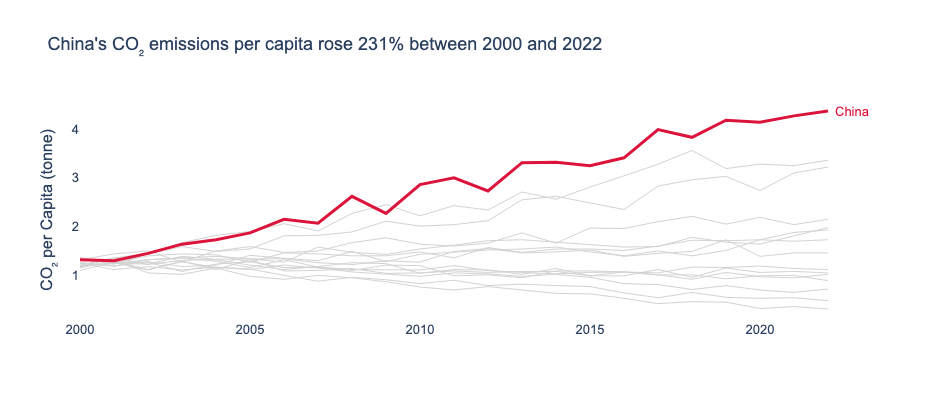

In [42]:
# step 2: plotly express figure

fig = px.line(
    data_frame=data,  
    x='Year', y='CO2_per_capita',
    color='group',                               
    line_group='Country',                        
    color_discrete_map={country: 'crimson', 'Other': 'lightgrey'},
    hover_name='Country', 
    hover_data={'group': False},
    labels={'CO2_per_capita': 'CO₂ per Capita (tonne)'},
    template='plotly_white',                     
    title=f"{country}'s CO₂ emissions per capita {'rose' if end > start else 'fell'} "
          f"{abs(pct[country]):.0f}% between 2000 and 2022",
    height=400
)

# step 3: additional customization

fig.update_traces(line_width=1)                               # thin context lines
fig.update_traces(line_width=3, selector={'name': country})   # thick highlight line
fig.add_annotation(x=2022, y=end, text=f'{country}', showarrow=False,
                   xanchor='left', xshift=5, font_color='crimson')   # direct label instead of legend
                                   

fig.update_layout(showlegend=False, 
                  yaxis=dict(showgrid=False),
                  xaxis=dict(showgrid=False, title=''),
                  font=dict(family='Arial', size=13))
fig.show()

## Task 2 — CO2 Emissions in Asia: one country highlighted
Same approach, filtered to Asia: we highlight the fastest-growing emitter.

In [43]:
# step 1: prep data

asia = df[df['Region'] == 'Asia']
mt = asia.pivot(index='Country', columns='Year', values='CO2_Mt')
country = (mt[2022] / mt[2000]).idxmax()          # fastest growth since 2000
start, end = mt.loc[country, [2000, 2022]]
data =  asia.assign(group=asia['Country'].where(asia['Country'] == country, 'Other'))


In [44]:
country

'China'

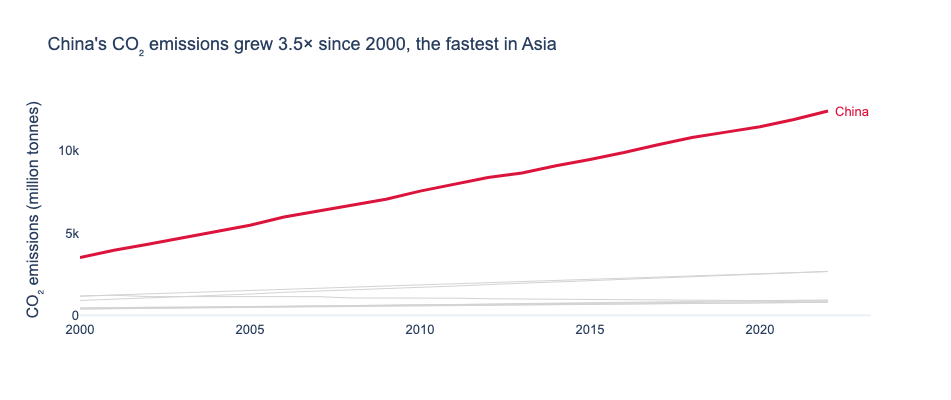

In [45]:
# step 2: plotly express figure

fig = px.line(
    data_frame=data,
    x='Year', y='CO2_Mt',
    color='group',
    color_discrete_map={country: 'crimson', 'Other': 'lightgrey'},
    hover_name='Country', 
    hover_data={'group': False},
    labels={'CO2_Mt': 'CO₂ emissions (million tonnes)'},
    template='plotly_white',
    title=f"{country}'s CO₂ emissions grew {end / start:.1f}× since 2000, the fastest in Asia",
    height=400
)

fig.update_traces(line_width=1)
fig.update_traces(line_width=3, selector={'name': country})
fig.add_annotation(x=2022, y=end, 
                   text=f'{country}', showarrow=False,
                   xanchor='left', xshift=5, font_color='crimson')

fig.update_layout(showlegend=False, 
                  yaxis=dict(showgrid=False),
                  xaxis=dict(showgrid=False, title=''),
                  font=dict(family='Arial', size=13))
fig.show()
